# VectorView: image and text search with CLIP embeddings

*Lab 14, Database Lab (Spring 2026).* The lab asks for three tasks on an animal image dataset:

1. **Image similarity search**: given a query image, return the most similar images.
2. **Classification by KNN voting**: predict a label from the labels of the nearest neighbours, with no trained classifier.
3. **Text to image search**: find images from a natural-language query.

Everything here runs **locally with no accounts**: CLIP embeddings are searched with exact cosine similarity in memory.
Pinecone (the lab's vector database for Tasks 1 and 2) and MongoDB Atlas Vector Search are included as **optional** sections at the
end that switch on only if you set `PINECONE_API_KEY` / `MONGODB_URI`.

On top of the lab tasks, this notebook **measures** the search quality with standard ranking metrics (Precision@k, Recall@k, MRR, nDCG@k),
KNN accuracy with a confusion matrix, zero-shot classification from text, and a comparison of two CLIP models (ViT-B/32 and ViT-B/16).

Run from the `notebooks/` folder; paths are relative.

In [1]:
import os
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
import time
import warnings
warnings.filterwarnings("ignore")   # before the heavy imports: transformers emits import-time warnings
import zipfile
import math
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm import tqdm
import torch
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import confusion_matrix, classification_report
from transformers.utils import logging as hf_logging

warnings.filterwarnings("ignore")
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
from huggingface_hub.utils import logging as hub_logging
hub_logging.set_verbosity_error()

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

DATASET_ZIP = Path("../data/animal_dataset.zip")
DATA_DIR = Path("../data")
DATASET_DIR = DATA_DIR / "animal_dataset"          # created by the extraction cell, not tracked in git
CACHE_DIR = DATA_DIR / "cache"                     # embedding cache, not tracked in git
FIG_DIR = Path("../docs/images")
for d in (CACHE_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

MODELS = {"ViT-B/32": "openai/clip-vit-base-patch32", "ViT-B/16": "openai/clip-vit-base-patch16"}
PRIMARY = "ViT-B/32"          # the lab's model; ViT-B/16 is used for the comparison
TOP_K_SIMILAR, TOP_K_KNN, TOP_K_CROSSMODAL = 5, 7, 5

print("device:", device, "| torch", torch.__version__)

device: cpu | torch 2.15.0+cpu


## 1. Dataset

In [2]:
# Extract the zip once (it stays in data/, the extracted folder is not tracked in git)
if not DATASET_DIR.exists():
    with zipfile.ZipFile(DATASET_ZIP) as z:
        z.extractall(DATA_DIR)

classes = sorted(d.name for d in DATASET_DIR.iterdir() if d.is_dir())
image_paths, labels = [], []
for c in classes:
    files = sorted(p for p in (DATASET_DIR / c).iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png"))
    image_paths += files
    labels += [c] * len(files)
labels = np.array(labels)
y = np.array([classes.index(l) for l in labels])
N = len(image_paths)

print(f"{N} images, {len(classes)} classes")
print({c: int((labels == c).sum()) for c in classes})
sizes = [Image.open(p).size for p in image_paths]
print("image size range (w x h): min", min(sizes), "max", max(sizes))
print("duplicate file names:", N - len({p.name for p in image_paths}))

500 images, 10 classes
{'Butterfly': 50, 'Cat': 50, 'Chicken': 50, 'Cow': 50, 'Dog': 50, 'Elephant': 50, 'Horse': 50, 'Sheep': 50, 'Spider': 50, 'Squirrel': 50}
image size range (w x h): min (120, 80) max (300, 300)
duplicate file names: 0


## 2. CLIP embeddings

CLIP maps images **and** text into the same 512-dimensional space. Embeddings are L2-normalised, so the dot product of two
vectors is their cosine similarity. Embeddings are cached in `data/cache/` after the first run.

In [3]:
def _as_tensor(x):
    # Different transformers versions return a tensor or a ModelOutput object
    if torch.is_tensor(x):
        return x
    pooled = getattr(x, "pooler_output", None)
    return pooled if pooled is not None else x[0]

def load_clip(name):
    model = CLIPModel.from_pretrained(name).to(device).eval()
    return model, CLIPProcessor.from_pretrained(name)

@torch.no_grad()
def embed_images(model, proc, paths, batch_size=32):
    out = []
    for i in range(0, len(paths), batch_size):
        imgs = [Image.open(p).convert("RGB") for p in paths[i:i + batch_size]]
        inputs = proc(images=imgs, return_tensors="pt").to(device)
        f = _as_tensor(model.get_image_features(**inputs))
        out.append((f / f.norm(dim=-1, keepdim=True)).cpu().numpy())
    E = np.vstack(out)
    assert E.shape[1] == model.config.projection_dim, "unexpected embedding size"
    return E

@torch.no_grad()
def embed_text(model, proc, texts):
    inputs = proc(text=list(texts), return_tensors="pt", padding=True).to(device)
    f = _as_tensor(model.get_text_features(**inputs))
    return (f / f.norm(dim=-1, keepdim=True)).cpu().numpy()

clips, EMB, embed_seconds = {}, {}, {}
for key, name in MODELS.items():
    clips[key] = load_clip(name)
    cache = CACHE_DIR / f"embeddings_{name.split('/')[-1]}.npy"
    t0 = time.time()
    if cache.exists() and np.load(cache).shape[0] == N:
        EMB[key] = np.load(cache)
    else:
        print(f"embedding {N} images with {key} ...")
        EMB[key] = embed_images(*clips[key], image_paths)
        np.save(cache, EMB[key])
    embed_seconds[key] = time.time() - t0
    print(f"{key:9s} {name:32s} embeddings {EMB[key].shape}  unit-norm: {np.allclose(np.linalg.norm(EMB[key], axis=1), 1, atol=1e-4)}")

ViT-B/32  openai/clip-vit-base-patch32     embeddings (500, 512)  unit-norm: True


ViT-B/16  openai/clip-vit-base-patch16     embeddings (500, 512)  unit-norm: True


## 3. Task 1: image similarity search

The search engine is an exact cosine-similarity ranking over the 500 embeddings. A query image is **excluded from its own results**
(file names are unique, so excluding by index is safe).

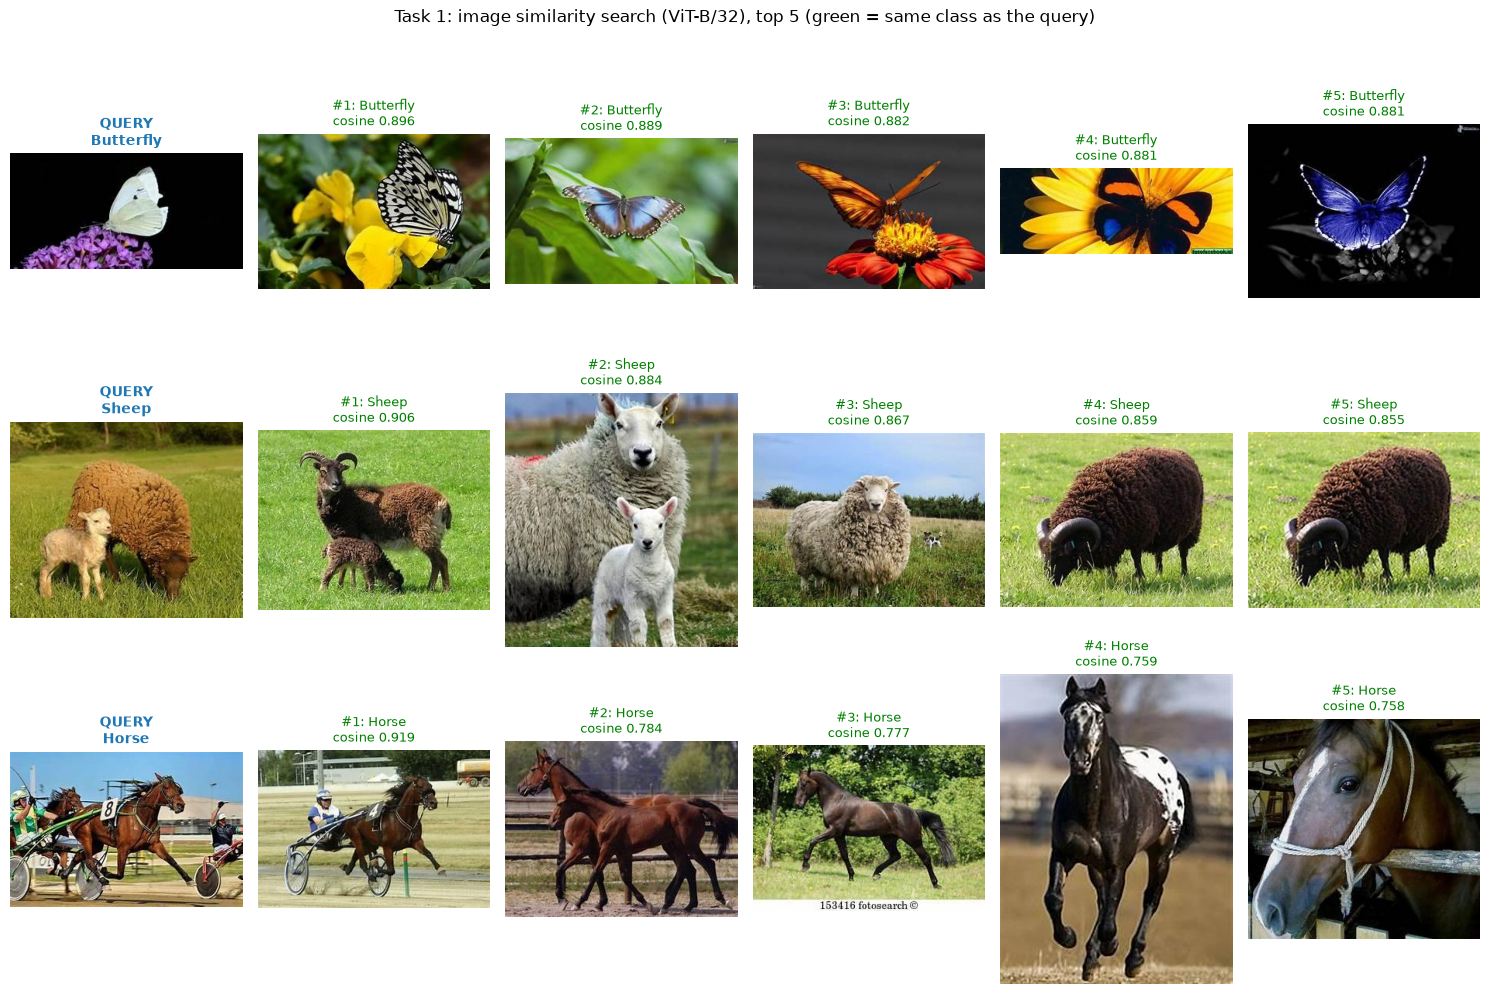

In [4]:
def search(E, query_vec, top_k, exclude_idx=None):
    # exact cosine similarity: embeddings are unit-norm, so a dot product is enough
    scores = E @ query_vec
    if exclude_idx is not None:
        scores = scores.copy()
        scores[exclude_idx] = -np.inf
    top = np.argsort(-scores)[:top_k]
    return top, scores[top]

def show_similarity(E, query_idx, top_k=TOP_K_SIMILAR, ax_row=None):
    top, sc = search(E, E[query_idx], top_k, exclude_idx=query_idx)
    for j, ax in enumerate(ax_row):
        ax.axis("off")
        if j == 0:
            ax.imshow(Image.open(image_paths[query_idx]))
            ax.set_title(f"QUERY\n{labels[query_idx]}", fontsize=10, color="tab:blue", fontweight="bold")
        else:
            i = top[j - 1]
            ax.imshow(Image.open(image_paths[i]))
            ok = labels[i] == labels[query_idx]
            ax.set_title(f"#{j}: {labels[i]}\ncosine {sc[j-1]:.3f}", fontsize=9, color="green" if ok else "red")

query_ids = [int(rng.integers(0, N)) for _ in range(3)]
fig, axes = plt.subplots(len(query_ids), TOP_K_SIMILAR + 1, figsize=(15, 3.3 * len(query_ids)))
for r, q in enumerate(query_ids):
    show_similarity(EMB[PRIMARY], q, ax_row=axes[r])
fig.suptitle(f"Task 1: image similarity search ({PRIMARY}), top {TOP_K_SIMILAR} (green = same class as the query)", fontsize=12, y=1.0)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_task1_image_similarity.png", dpi=130, bbox_inches="tight")
plt.show()

### How good is the retrieval? Ranking metrics

Looking at three queries proves little. Here **every one of the 500 images is used as a query** against the other 499 (leave-one-out).
An image is *relevant* if it has the same class as the query (49 relevant images per query).

- **Precision@k**: fraction of the top k that are relevant.
- **Recall@k**: fraction of the 49 relevant images found in the top k.
- **MRR**: mean of 1 / rank of the first relevant result.
- **nDCG@k**: ranking quality that rewards relevant results appearing early (binary relevance).

A random ranking is the baseline.

In [5]:
def retrieval_metrics(sims, rel_matrix, ks=(1, 5, 10)):
    # sims: (Q, N) similarity of each query to every item (queries excluded from their own results beforehand)
    # rel_matrix: (Q, N) boolean relevance
    order = np.argsort(-sims, axis=1)
    rel = np.take_along_axis(rel_matrix, order, axis=1)
    n_rel = rel_matrix.sum(axis=1)
    out = {}
    first = rel.argmax(axis=1) + 1
    out["MRR"] = float(np.mean(1.0 / first))
    for k in ks:
        top = rel[:, :k]
        out[f"P@{k}"] = float(top.mean())
        out[f"R@{k}"] = float(np.mean(top.sum(axis=1) / n_rel))
        disc = 1.0 / np.log2(np.arange(2, k + 2))
        dcg = (top * disc).sum(axis=1)
        idcg = np.array([disc[:int(min(k, n))].sum() for n in n_rel])
        out[f"nDCG@{k}"] = float(np.mean(dcg / idcg))
    return out

def loo_sims(E):
    s = E @ E.T
    np.fill_diagonal(s, -np.inf)       # a query never retrieves itself
    return s

rel_img = (y[:, None] == y[None, :]) & ~np.eye(N, dtype=bool)

# Random-ranking baseline (average over 20 random rankings)
rand = [retrieval_metrics(np.where(np.eye(N, dtype=bool), -np.inf, rng.random((N, N))), rel_img) for _ in range(20)]
baseline = {k: float(np.mean([r[k] for r in rand])) for k in rand[0]}

img_metrics = {m: retrieval_metrics(loo_sims(EMB[m]), rel_img) for m in MODELS}
cols = ["P@1", "P@5", "P@10", "R@5", "R@10", "MRR", "nDCG@10"]
print(f"Image to image retrieval, leave-one-out over {N} queries (relevant = same class, 49 per query)\n")
print(f"{'':22s}" + "".join(f"{c:>9s}" for c in cols))
print(f"{'random ranking':22s}" + "".join(f"{baseline[c]:>9.3f}" for c in cols))
for m in MODELS:
    print(f"{'CLIP ' + m:22s}" + "".join(f"{img_metrics[m][c]:>9.3f}" for c in cols))

Image to image retrieval, leave-one-out over 500 queries (relevant = same class, 49 per query)

                            P@1      P@5     P@10      R@5     R@10      MRR  nDCG@10
random ranking            0.097    0.096    0.098    0.010    0.020    0.251    0.097
CLIP ViT-B/32             0.990    0.978    0.971    0.100    0.198    0.993    0.974
CLIP ViT-B/16             0.988    0.985    0.978    0.101    0.200    0.992    0.981


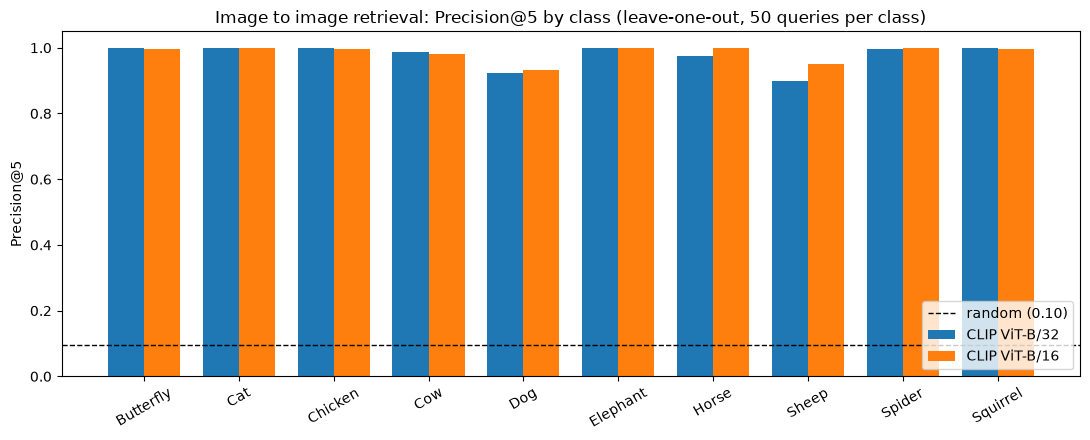

{'Butterfly': 1.0, 'Cat': 1.0, 'Chicken': 1.0, 'Cow': 0.988, 'Dog': 0.924, 'Elephant': 1.0, 'Horse': 0.976, 'Sheep': 0.9, 'Spider': 0.996, 'Squirrel': 1.0}


In [6]:
# Figure 2: precision@5 per class for both models
def per_class_p_at_k(E, k=5):
    s = loo_sims(E)
    top = np.argsort(-s, axis=1)[:, :k]
    hit = (y[top] == y[:, None]).mean(axis=1)
    return np.array([hit[y == c].mean() for c in range(len(classes))])

pc = {m: per_class_p_at_k(EMB[m]) for m in MODELS}
x = np.arange(len(classes)); w = 0.38
plt.figure(figsize=(11, 4.5))
for i, m in enumerate(MODELS):
    plt.bar(x + (i - 0.5) * w, pc[m], w, label=f"CLIP {m}")
plt.axhline(baseline["P@5"], color="black", linestyle="--", linewidth=1, label=f"random ({baseline['P@5']:.2f})")
plt.xticks(x, classes, rotation=30)
plt.ylabel("Precision@5")
plt.ylim(0, 1.05)
plt.title("Image to image retrieval: Precision@5 by class (leave-one-out, 50 queries per class)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_precision_at_5_by_class.png", dpi=130, bbox_inches="tight")
plt.show()
print({c: round(float(v), 3) for c, v in zip(classes, pc[PRIMARY])})

## 4. Task 2: classification by KNN voting

The 500 embeddings are the whole "training set". An image is classified by **majority vote of its K nearest neighbours**
(the image itself excluded). Voting ties go to the class whose neighbour appears first (nearest). Evaluating every image
this way is leave-one-out cross-validation.

In [7]:
def knn_predict(E, k):
    s = loo_sims(E)
    nn = np.argsort(-s, axis=1)[:, :k]
    preds = []
    for row in nn:
        votes = Counter(y[row].tolist())          # insertion order = nearest first, so ties go to the nearest neighbour
        preds.append(max(votes, key=lambda c: votes[c]))
    return np.array(preds)

def wilson(correct, n, z=1.96):
    p = correct / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

ks = list(range(1, 16))
knn_acc = {m: [float((knn_predict(EMB[m], k) == y).mean()) for k in ks] for m in MODELS}

print(f"Leave-one-out KNN accuracy ({N} images; random guessing = {1/len(classes):.1%})")
print(f"{'K':>3s}" + "".join(f"{('CLIP ' + m):>16s}" for m in MODELS))
for k in (1, 3, 5, 7, 9, 15):
    print(f"{k:>3d}" + "".join(f"{knn_acc[m][k-1]:>16.3f}" for m in MODELS))
for m in MODELS:
    c = round(knn_acc[m][TOP_K_KNN - 1] * N)
    lo, hi = wilson(c, N)
    print(f"{m}, K={TOP_K_KNN}: {c}/{N} correct = {c/N:.1%}  (95% CI {lo:.1%} to {hi:.1%})")

Leave-one-out KNN accuracy (500 images; random guessing = 10.0%)
  K   CLIP ViT-B/32   CLIP ViT-B/16
  1           0.990           0.988
  3           0.986           0.994
  5           0.988           0.994
  7           0.988           0.996
  9           0.988           0.996
 15           0.990           0.994
ViT-B/32, K=7: 494/500 correct = 98.8%  (95% CI 97.4% to 99.4%)
ViT-B/16, K=7: 498/500 correct = 99.6%  (95% CI 98.6% to 99.9%)


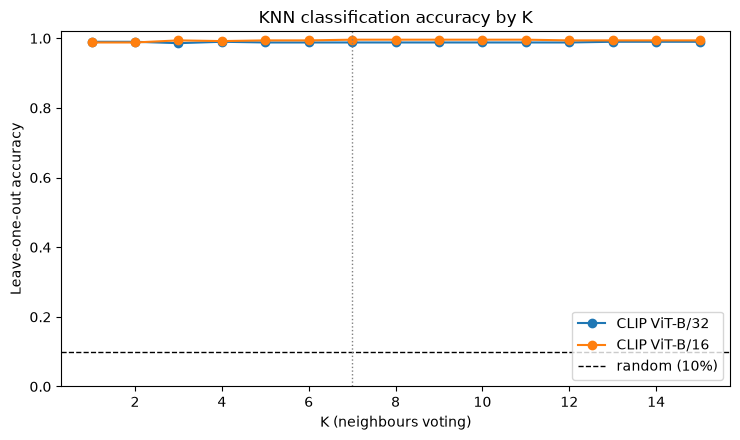

In [8]:
# Figure 3: accuracy against K
plt.figure(figsize=(7.5, 4.5))
for m in MODELS:
    plt.plot(ks, knn_acc[m], marker="o", label=f"CLIP {m}")
plt.axhline(1 / len(classes), color="black", linestyle="--", linewidth=1, label="random (10%)")
plt.axvline(TOP_K_KNN, color="grey", linestyle=":", linewidth=1)
plt.xlabel("K (neighbours voting)")
plt.ylabel("Leave-one-out accuracy")
plt.ylim(0.0, 1.02)
plt.title("KNN classification accuracy by K")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_knn_accuracy_by_k.png", dpi=130, bbox_inches="tight")
plt.show()

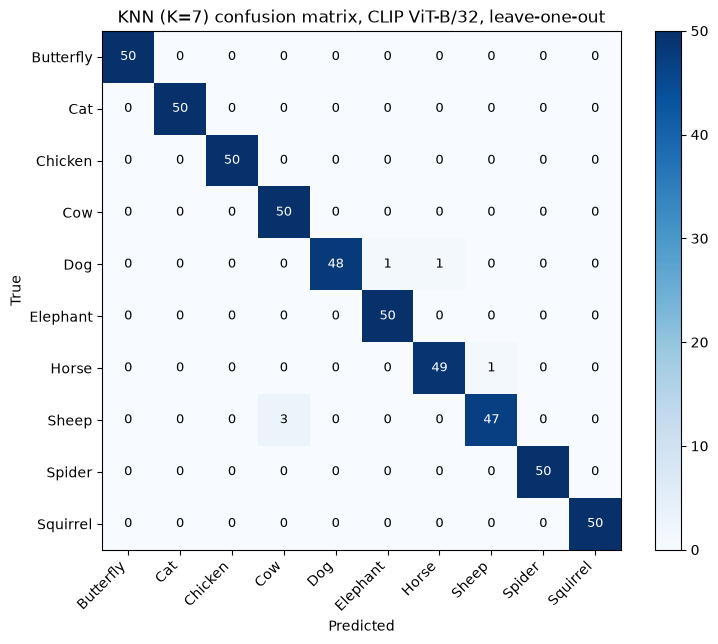

              precision    recall  f1-score   support

   Butterfly      1.000     1.000     1.000        50
         Cat      1.000     1.000     1.000        50
     Chicken      1.000     1.000     1.000        50
         Cow      0.943     1.000     0.971        50
         Dog      1.000     0.960     0.980        50
    Elephant      0.980     1.000     0.990        50
       Horse      0.980     0.980     0.980        50
       Sheep      0.979     0.940     0.959        50
      Spider      1.000     1.000     1.000        50
    Squirrel      1.000     1.000     1.000        50

    accuracy                          0.988       500
   macro avg      0.988     0.988     0.988       500
weighted avg      0.988     0.988     0.988       500

Most common confusions (true -> predicted, count): [('Sheep', 'Cow', 3), ('Dog', 'Elephant', 1), ('Dog', 'Horse', 1), ('Horse', 'Sheep', 1)]


In [9]:
# Figure 4: confusion matrix and per-class report for the primary model, K = 7
pred = knn_predict(EMB[PRIMARY], TOP_K_KNN)
cm = confusion_matrix(y, pred)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(classes)), classes, rotation=45, ha="right")
ax.set_yticks(range(len(classes)), classes)
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"KNN (K={TOP_K_KNN}) confusion matrix, CLIP {PRIMARY}, leave-one-out")
plt.colorbar(im)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_knn_confusion_matrix.png", dpi=130, bbox_inches="tight")
plt.show()
print(classification_report(y, pred, target_names=classes, digits=3))
off = [(classes[i], classes[j], int(cm[i, j])) for i in range(len(classes)) for j in range(len(classes)) if i != j and cm[i, j] > 0]
print("Most common confusions (true -> predicted, count):", sorted(off, key=lambda t: -t[2])[:6])

## 5. Task 3: text to image search

The text encoder puts a sentence in the same space as the images, so the same cosine search works with a text vector as the query.
(The lab suggests MongoDB Atlas Vector Search for this task. The free Atlas tier was not available to me, so the search below is
exact in-memory cosine; an optional Atlas version is at the end of the notebook.)

'a cute fluffy cat': Cat (0.287), Cat (0.286), Cat (0.281), Cat (0.279), Cat (0.279)
'an elephant in the wild': Elephant (0.307), Elephant (0.306), Elephant (0.306), Elephant (0.305), Elephant (0.303)
'a colorful butterfly on a flower': Butterfly (0.315), Butterfly (0.307), Butterfly (0.304), Butterfly (0.304), Butterfly (0.303)
'a dog playing outdoors': Dog (0.280), Dog (0.265), Dog (0.261), Dog (0.260), Dog (0.260)
'a horse galloping in a field': Horse (0.305), Horse (0.300), Horse (0.296), Horse (0.292), Horse (0.289)


'spider on a web': Spider (0.289), Spider (0.282), Spider (0.279), Spider (0.277), Spider (0.274)


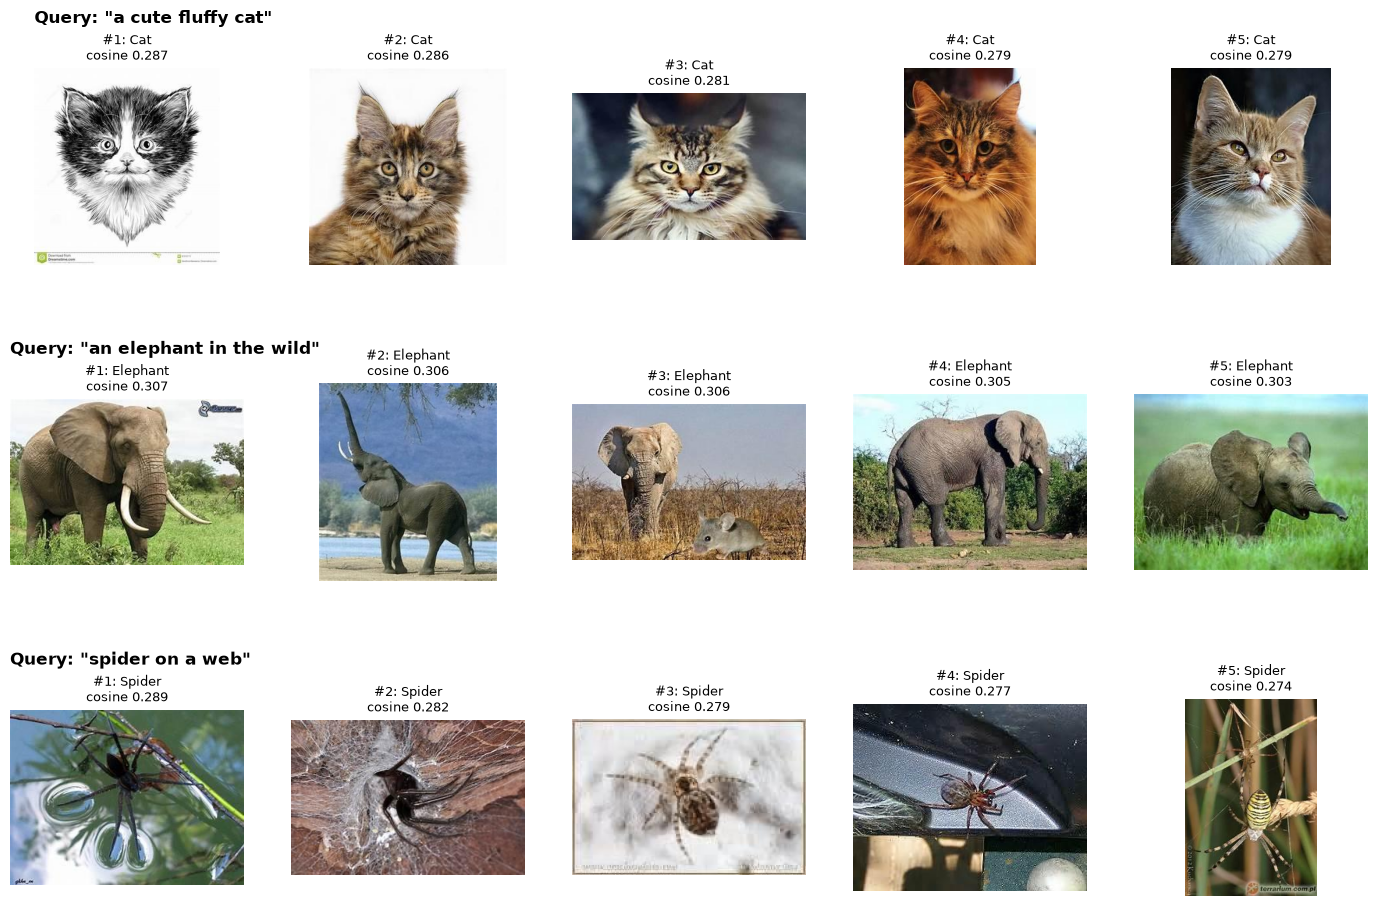

In [10]:
def text_search(model_key, text, top_k=TOP_K_CROSSMODAL):
    t = embed_text(*clips[model_key], [text])[0]
    return search(EMB[model_key], t, top_k)

demo_queries = ["a cute fluffy cat", "an elephant in the wild", "a colorful butterfly on a flower",
                "a dog playing outdoors", "a horse galloping in a field", "spider on a web"]
for q in demo_queries:
    top, sc = text_search(PRIMARY, q)
    print(f"'{q}': " + ", ".join(f"{labels[i]} ({s:.3f})" for i, s in zip(top, sc)))

fig, axes = plt.subplots(3, TOP_K_CROSSMODAL, figsize=(14, 9))
for r, q in enumerate(["a cute fluffy cat", "an elephant in the wild", "spider on a web"]):
    top, sc = text_search(PRIMARY, q)
    for j, ax in enumerate(axes[r]):
        ax.imshow(Image.open(image_paths[top[j]]))
        ax.axis("off")
        ax.set_title(f"#{j+1}: {labels[top[j]]}\ncosine {sc[j]:.3f}", fontsize=9)
fig.subplots_adjust(left=0.02, right=0.99, top=0.94, bottom=0.02, hspace=0.6)
for r, q in enumerate(["a cute fluffy cat", "an elephant in the wild", "spider on a web"]):
    pos = axes[r][0].get_position()
    fig.text(pos.x0, pos.y1 + 0.05, f'Query: "{q}"', fontsize=12, fontweight="bold")
plt.savefig(FIG_DIR / "05_task3_text_to_image.png", dpi=130, bbox_inches="tight")
plt.show()

### Measuring text to image retrieval and zero-shot classification

One prompt per class ("a photo of a cat", ...). Two evaluations, using the same CLIP text encoder:

- **Text to image retrieval**: relevant = images of that class (50 per prompt). Precision@k, average precision (AP), MRR, averaged over the 10 prompts.
- **Zero-shot classification**: label each image with the class whose prompt is most similar. No labelled images are used at all, which makes it a useful comparison for KNN, which uses the other 499 labels.

In [11]:
prompts = [f"a photo of a {c.lower()}" for c in classes]

def text_metrics(m):
    T = embed_text(*clips[m], prompts)            # (10, 512)
    S = T @ EMB[m].T                              # (10, N) prompt to image similarity
    rel = (y[None, :] == np.arange(len(classes))[:, None])
    order = np.argsort(-S, axis=1)
    r = np.take_along_axis(rel, order, axis=1)
    out = {"P@5": float(r[:, :5].mean()), "P@10": float(r[:, :10].mean()), "P@50": float(r[:, :50].mean()),
           "MRR": float(np.mean(1 / (r.argmax(axis=1) + 1)))}
    ap = [(np.cumsum(row) / np.arange(1, N + 1))[row].mean() for row in r]
    out["mAP"] = float(np.mean(ap))
    zs_pred = S.argmax(axis=0)
    out["zero-shot acc"] = float((zs_pred == y).mean())
    return out, zs_pred

txt, zs = {}, {}
for m in MODELS:
    txt[m], zs[m] = text_metrics(m)
rand_p = 50 / N
print(f"Text to image retrieval ({len(classes)} class prompts, 50 relevant images each; random P@k = {rand_p:.2f}) and zero-shot classification\n")
cols_t = ["P@5", "P@10", "P@50", "MRR", "mAP", "zero-shot acc"]
print(f"{'':16s}" + "".join(f"{c:>15s}" for c in cols_t))
for m in MODELS:
    print(f"{'CLIP ' + m:16s}" + "".join(f"{txt[m][c]:>15.3f}" for c in cols_t))

for m in MODELS:
    wrong = [(classes[t], classes[p]) for t, p in zip(y, zs[m]) if t != p]
    print(f"\nZero-shot {m}: {int((zs[m]==y).sum())}/{N} correct; most frequent confusions:", Counter(wrong).most_common(4))

Text to image retrieval (10 class prompts, 50 relevant images each; random P@k = 0.10) and zero-shot classification

                            P@5           P@10           P@50            MRR            mAP  zero-shot acc
CLIP ViT-B/32             1.000          1.000          0.938          1.000          0.979          0.990
CLIP ViT-B/16             1.000          1.000          0.958          1.000          0.987          1.000

Zero-shot ViT-B/32: 495/500 correct; most frequent confusions: [(('Sheep', 'Cow'), 2), (('Dog', 'Horse'), 1), (('Dog', 'Sheep'), 1), (('Spider', 'Butterfly'), 1)]

Zero-shot ViT-B/16: 500/500 correct; most frequent confusions: []


In [12]:
# A deliberately vague query: where do the results come from?
for q in ["an animal", "a photo of something alive"]:
    top, sc = text_search(PRIMARY, q, top_k=20)
    print(f"'{q}' top 20 by class: { {str(k): v for k, v in Counter(labels[top]).most_common()} }")

'an animal' top 20 by class: {'Elephant': 6, 'Chicken': 4, 'Cow': 3, 'Horse': 3, 'Squirrel': 3, 'Spider': 1}
'a photo of something alive' top 20 by class: {'Spider': 16, 'Butterfly': 4}


## 6. Model comparison and search speed

In [13]:
rows = []
for m in MODELS:
    rows.append((f"CLIP {m}", knn_acc[m][TOP_K_KNN - 1], txt[m]["zero-shot acc"], img_metrics[m]["P@5"], img_metrics[m]["MRR"],
                 img_metrics[m]["nDCG@10"], txt[m]["P@10"], txt[m]["mAP"]))
hdr = ["KNN acc (K=7)", "zero-shot acc", "img P@5", "img MRR", "img nDCG@10", "text P@10", "text mAP"]
print(f"{'':12s}" + "".join(f"{h:>15s}" for h in hdr))
for r in rows:
    print(f"{r[0]:12s}" + "".join(f"{v:>15.3f}" for v in r[1:]))

# Search speed of the exact in-memory search (the optional Pinecone/Atlas sections do not run without an account)
E = EMB[PRIMARY]; q = E[0]
t0 = time.perf_counter()
for _ in range(1000):
    top = np.argsort(-(E @ q))[:5]
ms = (time.perf_counter() - t0) / 1000 * 1000
print(f"\nExact in-memory top-5 search over {N} vectors: {ms:.3f} ms per query (single CPU thread, no network)")

              KNN acc (K=7)  zero-shot acc        img P@5        img MRR    img nDCG@10      text P@10       text mAP
CLIP ViT-B/32          0.988          0.990          0.978          0.993          0.974          1.000          0.979
CLIP ViT-B/16          0.996          1.000          0.985          0.992          0.981          1.000          0.987

Exact in-memory top-5 search over 500 vectors: 0.069 ms per query (single CPU thread, no network)


## 7. Optional: Pinecone (the lab's vector database for Tasks 1 and 2)

Skipped unless the environment variable `PINECONE_API_KEY` is set. This is the original lab implementation with the key moved
out of the notebook. It was **not executed in this published run**; the screenshots in `docs/images/original-run/` come from the
original Colab run against Pinecone. Install the extra package first: `pip install -r requirements-optional.txt`.

In [14]:
PINECONE_API_KEY = os.getenv("PINECONE_API_KEY")
if not PINECONE_API_KEY:
    print("Skipped: set PINECONE_API_KEY to run the Pinecone version of Tasks 1 and 2.")
else:
    from pinecone import Pinecone, ServerlessSpec
    PINECONE_INDEX = os.getenv("PINECONE_INDEX", "animal-embeddings")
    pc = Pinecone(api_key=PINECONE_API_KEY)
    dim = EMB[PRIMARY].shape[1]
    if PINECONE_INDEX not in [i.name for i in pc.list_indexes()]:
        pc.create_index(name=PINECONE_INDEX, dimension=dim, metric="cosine",
                        spec=ServerlessSpec(cloud="aws", region="us-east-1"))
        while not pc.describe_index(PINECONE_INDEX).status["ready"]:
            time.sleep(2)
    index = pc.Index(PINECONE_INDEX)
    vectors = [{"id": f"img_{i:04d}", "values": EMB[PRIMARY][i].tolist(),
                "metadata": {"filename": image_paths[i].name, "label": str(labels[i])}} for i in range(N)]
    for i in range(0, N, 100):
        index.upsert(vectors=vectors[i:i + 100])
    # leave-one-out KNN through Pinecone, to compare with the exact in-memory result
    hits = 0
    for i in tqdm(range(N), desc="Pinecone KNN"):
        res = index.query(vector=EMB[PRIMARY][i].tolist(), top_k=TOP_K_KNN + 1, include_metadata=True)
        nbrs = [m for m in res.matches if m.id != f"img_{i:04d}"][:TOP_K_KNN]
        votes = Counter(m.metadata["label"] for m in nbrs)
        hits += max(votes, key=lambda c: votes[c]) == labels[i]
    print(f"Pinecone leave-one-out KNN accuracy (K={TOP_K_KNN}): {hits / N:.3f} "
          f"(exact in-memory: {knn_acc[PRIMARY][TOP_K_KNN - 1]:.3f})")

Skipped: set PINECONE_API_KEY to run the Pinecone version of Tasks 1 and 2.


## 8. Optional: MongoDB Atlas Vector Search for Task 3

Skipped unless `MONGODB_URI` is set. Needs an Atlas cluster with a **vector search index** named `vector_index` on the field
`embedding` (512 dimensions, cosine). Not executed in this published run. Install the extra package first:
`pip install -r requirements-optional.txt`.

```json
{ "fields": [ { "type": "vector", "path": "embedding", "numDimensions": 512, "similarity": "cosine" } ] }
```

In [15]:
MONGODB_URI = os.getenv("MONGODB_URI")
if not MONGODB_URI:
    print("Skipped: set MONGODB_URI to run Task 3 on MongoDB Atlas Vector Search.")
else:
    from pymongo import MongoClient
    coll = MongoClient(MONGODB_URI)[os.getenv("MONGODB_DB", "vectorview")][os.getenv("MONGODB_COLLECTION", "animal_images")]
    if coll.count_documents({}) < N:
        coll.delete_many({})
        coll.insert_many([{"filename": image_paths[i].name, "label": str(labels[i]),
                           "embedding": EMB[PRIMARY][i].tolist()} for i in range(N)])
    qv = embed_text(*clips[PRIMARY], ["a cute fluffy cat"])[0].tolist()
    pipeline = [{"$vectorSearch": {"index": "vector_index", "path": "embedding", "queryVector": qv,
                                   "numCandidates": 100, "limit": TOP_K_CROSSMODAL}},
                {"$project": {"_id": 0, "filename": 1, "label": 1, "score": {"$meta": "vectorSearchScore"}}}]
    for doc in coll.aggregate(pipeline):
        print(doc)

Skipped: set MONGODB_URI to run Task 3 on MongoDB Atlas Vector Search.


## Summary (every number below is printed by the cells above)

**Data.** 500 images, 10 classes with 50 each, 120x80 to 300x300 pixels, no duplicate files.

**Task 1, image similarity** (leave-one-out over 500 queries; relevant = same class; random ranking for reference):

| Model | P@1 | P@5 | P@10 | MRR | nDCG@10 |
|---|---|---|---|---|---|
| Random ranking | 0.097 | 0.096 | 0.098 | 0.251 | 0.097 |
| CLIP ViT-B/32 | 0.990 | 0.978 | 0.971 | 0.993 | 0.974 |
| CLIP ViT-B/16 | 0.988 | 0.985 | 0.978 | 0.992 | 0.981 |

The weakest classes for ViT-B/32 are Sheep (P@5 0.900) and Dog (0.924).

**Task 2, KNN voting (K = 7, leave-one-out):** ViT-B/32 98.8% (494 of 500; 95% CI 97.4% to 99.4%), ViT-B/16 99.6% (498 of 500; 95% CI 98.6% to 99.9%), random guessing 10%.
The six ViT-B/32 mistakes: Sheep predicted as Cow (3), Dog as Elephant (1), Dog as Horse (1), Horse as Sheep (1).

**Task 3, text to image:** with one prompt per class ("a photo of a cat"), Precision@10 is 1.000 for both models, mAP is 0.979 (B/32) and 0.987 (B/16),
and zero-shot classification from the prompts alone, with no labelled images, reaches 99.0% (495 of 500) and 100% (500 of 500).
A deliberately vague query ("an animal") returns a top 20 spread over six of the ten classes.

**Reading the model comparison.** ViT-B/16 is slightly ahead on most aggregates, but its KNN lead is 4 images out of 500 and the
confidence intervals overlap. On a dataset this easy, both models are close to the ceiling, so the data cannot separate them.

**Speed.** Exact in-memory search takes about 0.1 ms per query over 500 vectors (single CPU thread, no network).

**Limitations.** A small, clean set of 500 classic animal photos, many of them catalogue-style web images; relevance is class level (same class), not instance level;
CLIP was trained on web-scale data, so some of these images may resemble its training data and the scores may flatter it; the Pinecone and
MongoDB Atlas sections were not executed in this run, so there is no measured comparison of those services.